# 02 — Analisis Exploratorio Univariado (EDA)
**Objetivo:** Analizar las distribuciones individuales, asimetria, valores atipicos y normalidad de las variables demograficas candidatas para el Indice Compuesto.

**Input:** `data/silver/wpp2024_countries_estimates.parquet`

---


## 2.1 Imports y carga de datos Silver
Cargamos el dataset depurado de paises y areas (1950–2023) y anadimos el mapeo oficial de continentes para comparaciones regionales.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

sys.path.insert(0, str(Path.cwd().parent))
from src.config import SILVER, FIGURES_EDA
from src.viz import setup_style, save_figure

setup_style()

# Cargar estimaciones Silver
df = pd.read_parquet(SILVER / 'wpp2024_countries_estimates.parquet')

# Mapeo oficial de regiones UN M49 (ParentID a Continente)
region_map = {
    910: 'Africa', 911: 'Africa', 912: 'Africa', 913: 'Africa', 914: 'Africa',
    5500: 'Asia', 906: 'Asia', 5501: 'Asia', 920: 'Asia', 922: 'Asia',
    923: 'Europe', 924: 'Europe', 925: 'Europe', 926: 'Europe',
    915: 'Latin America & Caribbean', 916: 'Latin America & Caribbean', 931: 'Latin America & Caribbean',
    918: 'Northern America',
    927: 'Oceania', 928: 'Oceania', 954: 'Oceania', 957: 'Oceania'
}
df['Continent'] = df['ParentID'].map(region_map)

print(f"Dimensiones cargadas: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Paises/Areas unicos: {df['Location'].nunique()}")
print(f"Rango de tiempo: {df['Time'].min()} - {df['Time'].max()}")

Dimensiones cargadas: 17,538 filas x 77 columnas
Paises/Areas unicos: 237
Rango de tiempo: 1950 - 2023


## 2.2 Distribuciones por epoca (KDE)
Evaluamos como han cambiado las distribuciones globales de los indicadores demograficos centrales en cuatro momentos clave: 1950, 1980, 2000 y 2023.

  💾 Saved: outputs\figures\eda\02_kde_epochs.png


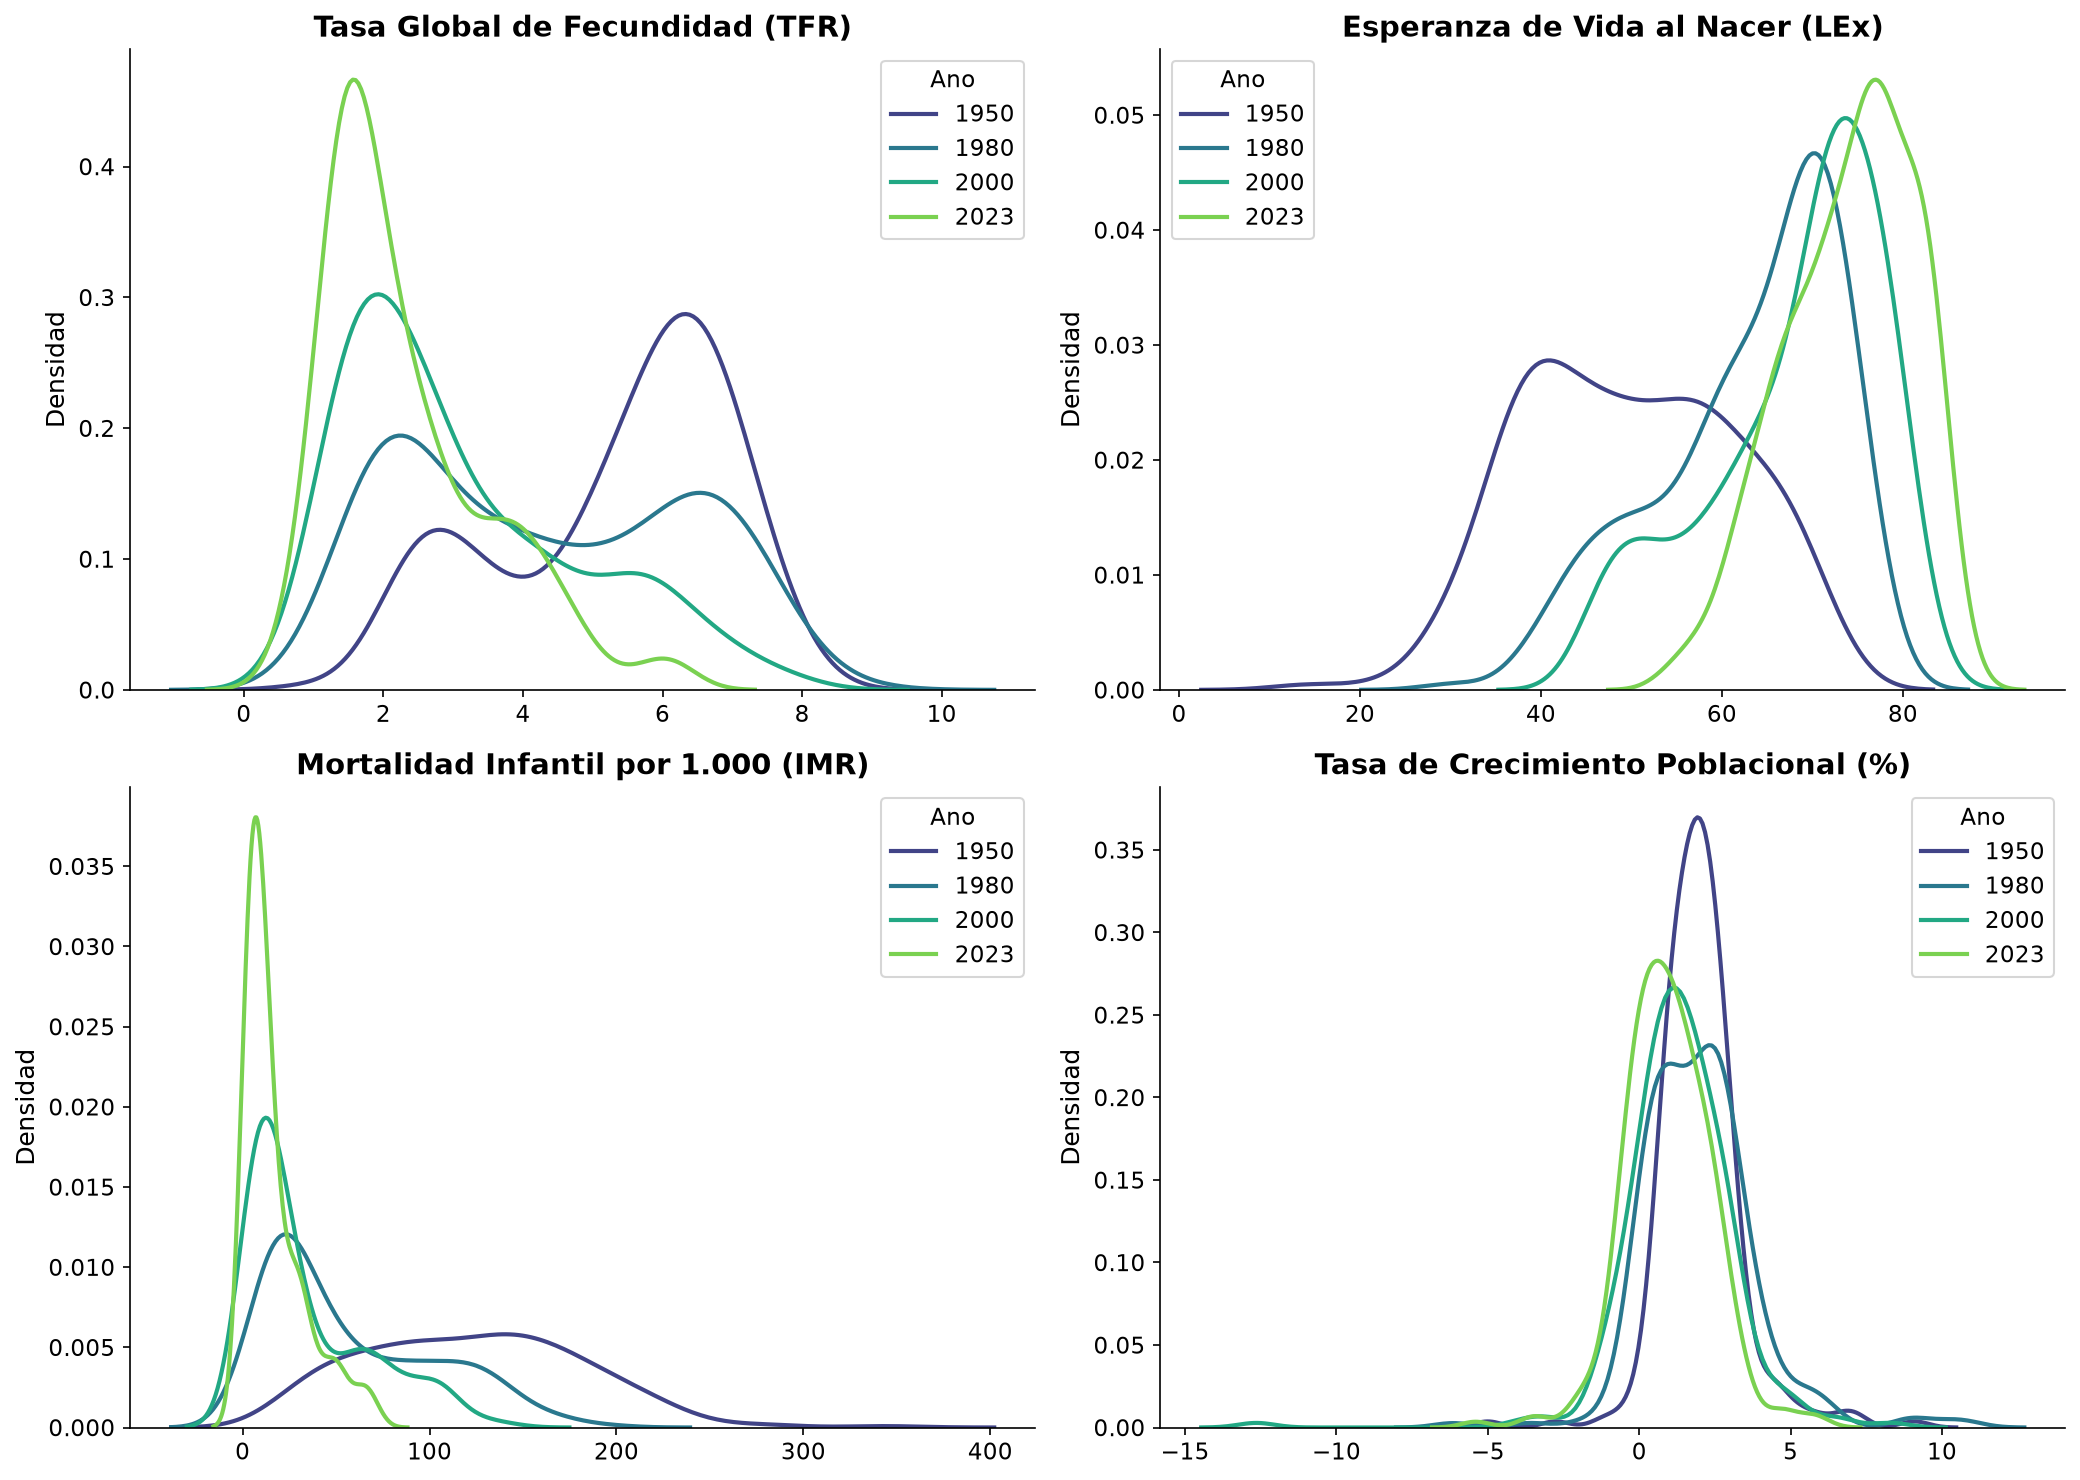

In [2]:
years_compare = [1950, 1980, 2000, 2023]
palette_years = sns.color_palette('viridis', len(years_compare))

vars_kde = ['TFR', 'LEx', 'IMR', 'PopGrowthRate']
titles_kde = [
    'Tasa Global de Fecundidad (TFR)',
    'Esperanza de Vida al Nacer (LEx)',
    'Mortalidad Infantil por 1.000 (IMR)',
    'Tasa de Crecimiento Poblacional (%)'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, (var, title) in enumerate(zip(vars_kde, titles_kde)):
    ax = axes[i]
    for year, color in zip(years_compare, palette_years):
        data_year = df[df['Time'] == year][var].dropna()
        sns.kdeplot(data=data_year, ax=ax, label=str(year), color=color, linewidth=2)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Densidad')
    ax.legend(title='Ano')

plt.tight_layout()
save_figure(fig, '02_kde_epochs', subdir='eda')
plt.show()

## Cambios a lo largo del tiempo
- Cambio en el número de hijos: La cantidad de hijos por mujer (Fecundidad) pasó de estar muy concentrada en niveles altos en 1950 (casi 6 hijos) a inclinarse hacia valores mucho más bajos en 2023, donde la mayoría de los países ya no tienen los nacimientos necesarios para reemplazar a su población actual (menos de 2.1 hijos).  
- Más años de vida y menos mortalidad: La esperanza de vida ha mejorado, unificándose alrededor de los 70 a 80 años para 2023, dejando atrás la división extrema entre países ricos y pobres que existía en 1950. Al mismo tiempo, las muertes de bebés cayeron drásticamente, acercándose a cero en casi todo el mundo.  
- Freno en el crecimiento poblacional: El crecimiento de la población se está estancando o volviendo negativo, lo que refleja que las regiones más avanzadas se están empezando a encoger demográficamente.  

## 2.3 Box y Violin Plots por Region
Comparamos la dispersion y variabilidad regional de los indicadores en el ano mas reciente de estimaciones (2023) para identificar disparidades estructurales entre continentes.

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_8108\1092850778.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_2023, x='Continent', y=var, ax=ax, palette='Set2')
C:\Users\USUARIO\AppData\Local\Temp\ipykernel_8108\1092850778.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_2023, x='Continent', y=var, ax=ax, palette='Set2')
C:\Users\USUARIO\AppData\Local\Temp\ipykernel_8108\1092850778.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_2023, x='Continent', y=var, ax=ax, palette='Set2')
C:\Users\USUARIO\AppData\

  💾 Saved: outputs\figures\eda\02_boxplot_regions_2023.png


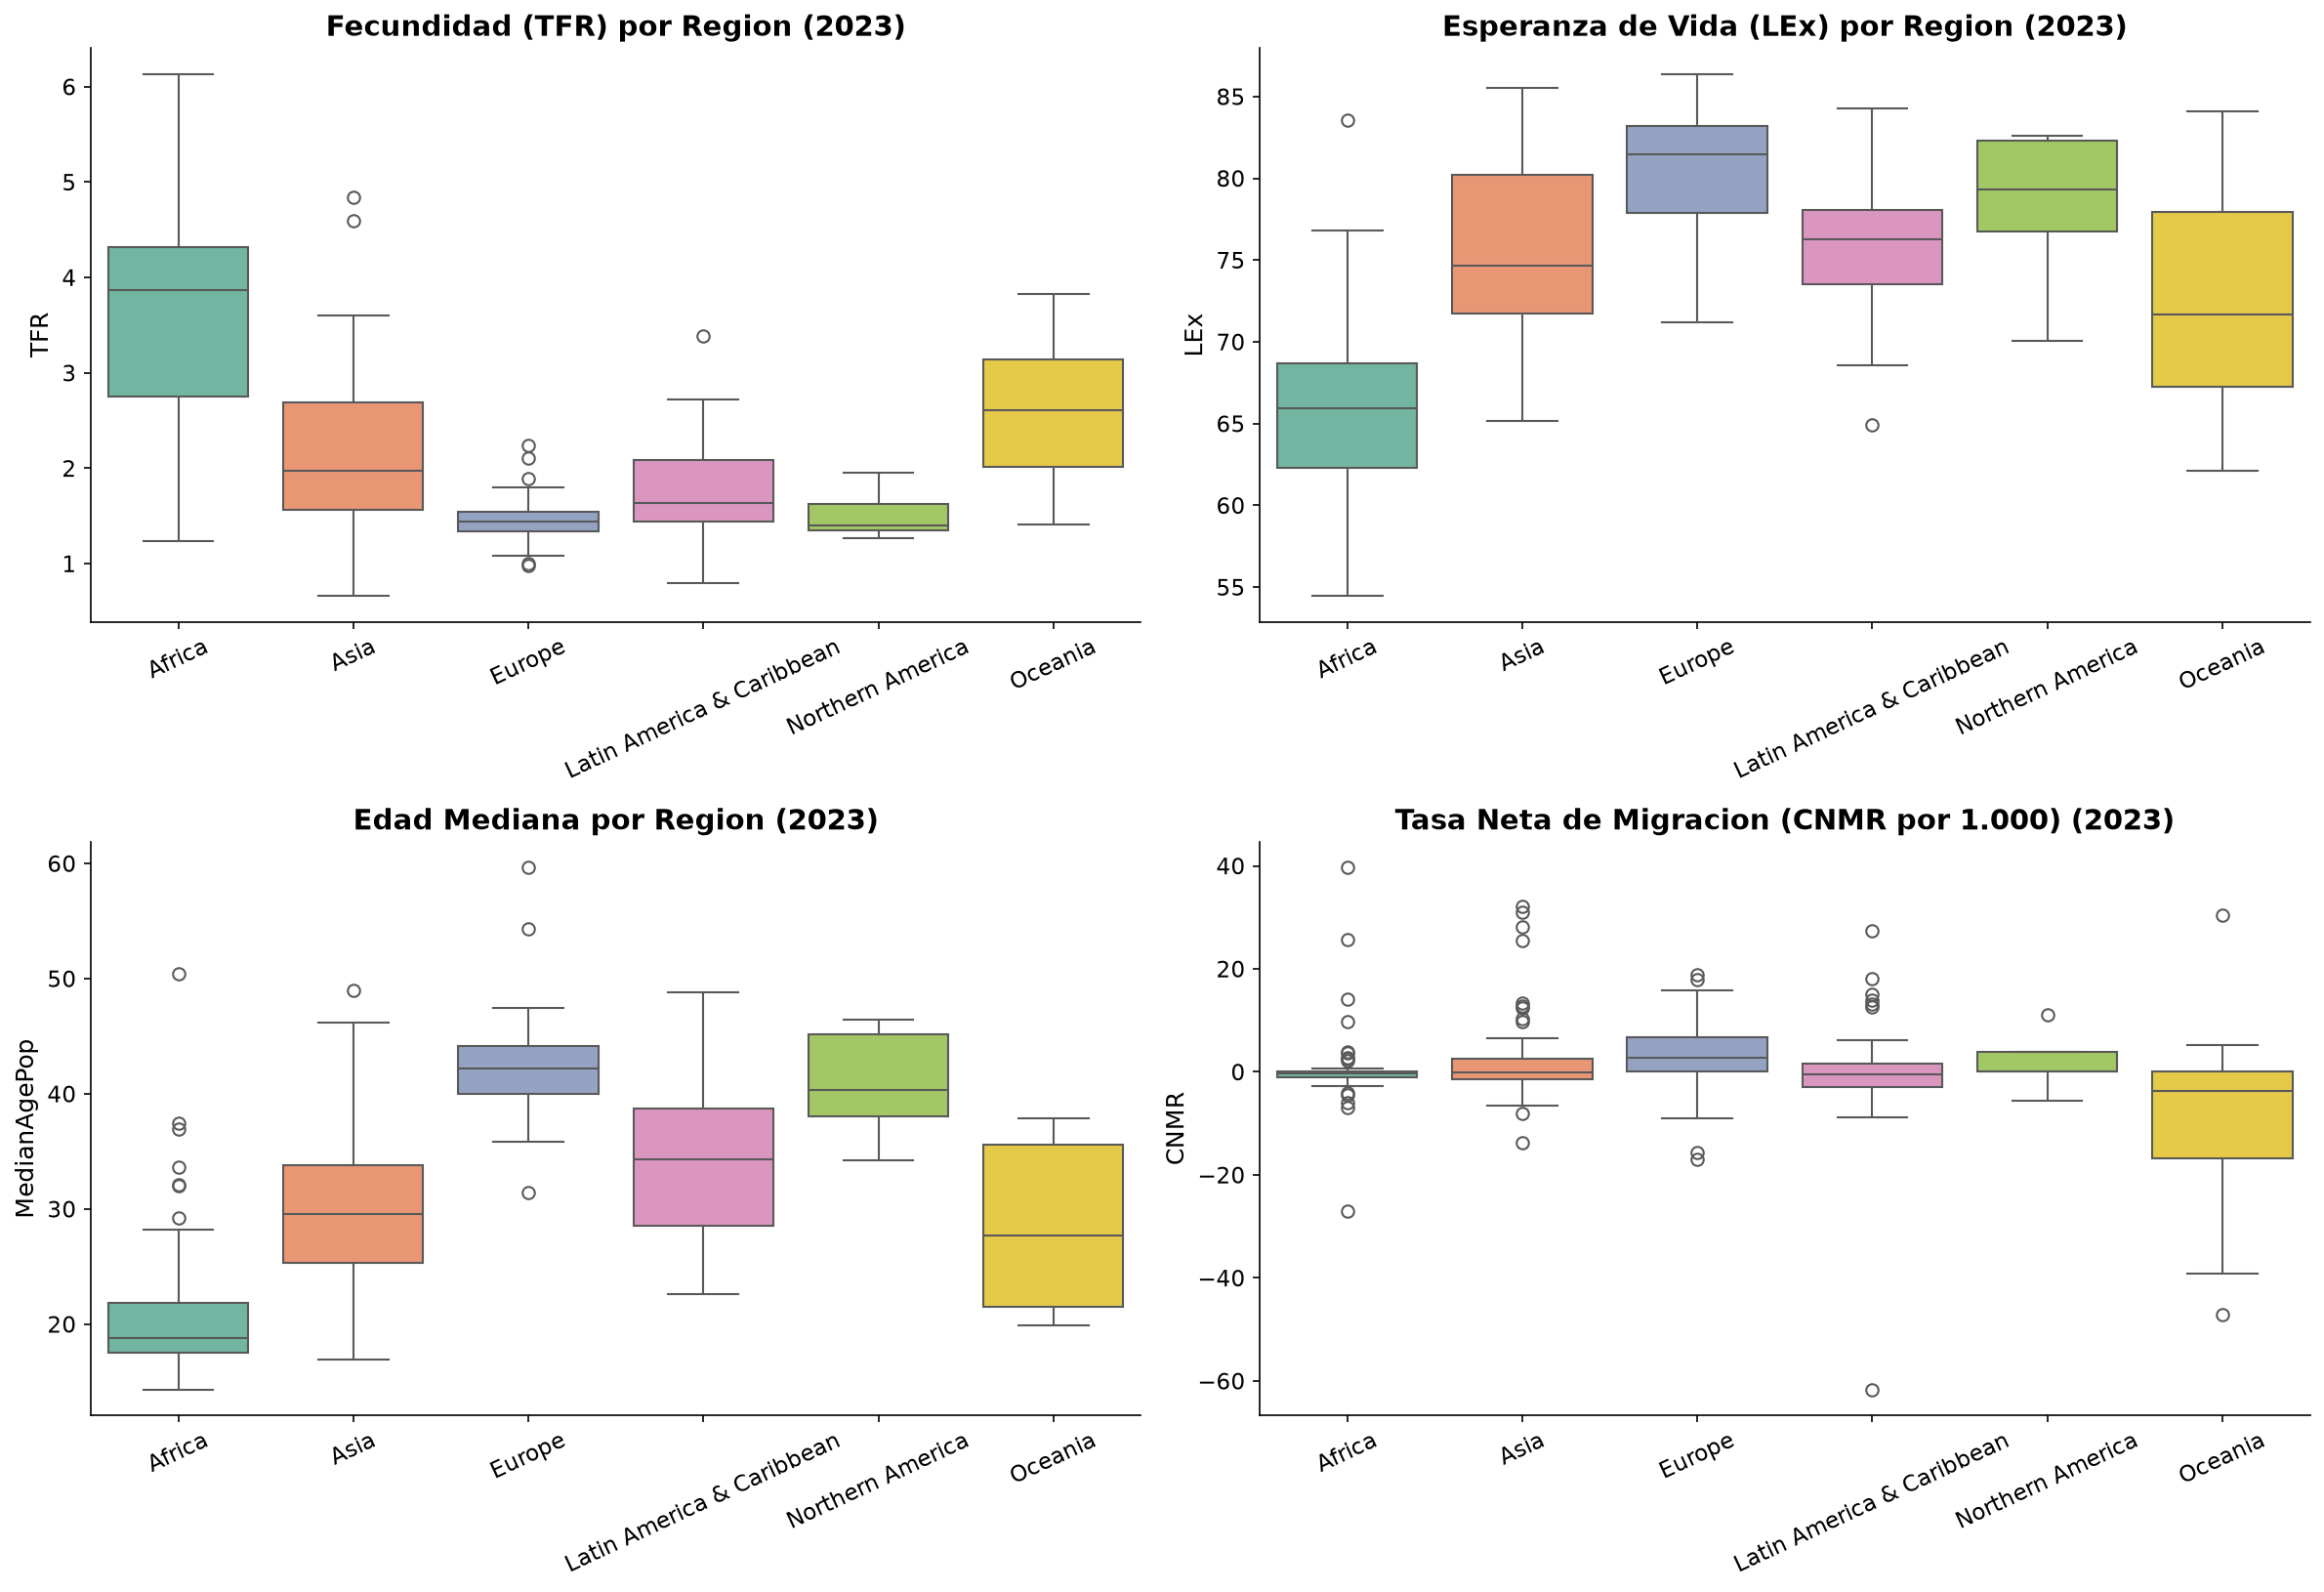

In [3]:
df_2023 = df[df['Time'] == 2023].copy()

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

vars_box = ['TFR', 'LEx', 'MedianAgePop', 'CNMR']
titles_box = [
    'Fecundidad (TFR) por Region (2023)',
    'Esperanza de Vida (LEx) por Region (2023)',
    'Edad Mediana por Region (2023)',
    'Tasa Neta de Migracion (CNMR por 1.000) (2023)'
]

for i, (var, title) in enumerate(zip(vars_box, titles_box)):
    ax = axes[i]
    sns.boxplot(data=df_2023, x='Continent', y=var, ax=ax, palette='Set2')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
save_figure(fig, '02_boxplot_regions_2023', subdir='eda')
plt.show()

## Diferencias entre las regiones (Para 2023)
- Brechas marcadas: Hay una gran distancia entre África, que sigue teniendo una población muy joven (con la mitad de su gente por debajo de los 20 años) y una menor esperanza de vida, frente a regiones como Europa o América del Norte, donde la población está muy envejecida (más de 40 años) y nacen muy pocos bebés.  
- Desigualdad dentro de los continentes: África y Asia son las regiones con mayores diferencias de salud y supervivencia entre sus propios países, evidenciando grandes desigualdades internas. En contraste, los países europeos tienen perfiles muy similares entre sí. 

## 2.4 Deteccion y Contextualizacion de Outliers Historicos
> **Principio de Rigor Demografico:** No se eliminan valores atipicos sin comprobar si responden a eventos historicos reales (guerras, genocidios, pandemias, crisis migratorias).

In [4]:
# Outliers extremos de esperanza de vida (LEx < 25 anos)
outliers_lex = df[df['LEx'] < 25][['Location', 'Time', 'LEx', 'IMR', 'Deaths']].sort_values('LEx')
print('Casos historicos extremos de minima esperanza de vida:')
display(outliers_lex.head(10))

# Outliers de migracion extrema (|CNMR| > 50 por 1.000 habitantes)
outliers_cnmr = df[df['CNMR'].abs() > 50][['Location', 'Time', 'CNMR', 'NetMigrations']].sort_values('CNMR', ascending=False)
print('Casos historicos de flujos migratorios extremos:')
display(outliers_cnmr.head(10))

# Outliers de fecundidad en 2023 (TFR maximo y minimo)
tfr_extreme = pd.concat([
    df_2023.nsmallest(5, 'TFR')[['Location', 'Time', 'TFR']],
    df_2023.nlargest(5, 'TFR')[['Location', 'Time', 'TFR']]
])
print('Fecundidad extrema en 2023 (Top 5 minimos y maximos):')
display(tfr_extreme)

Casos historicos extremos de minima esperanza de vida:


,Location,Time,LEx,IMR,Deaths
1148,South Sudan,1988,10.9891,423.8092,376.879
6021,Cambodia,1977,11.2952,177.4197,527.086
6022,Cambodia,1978,11.5726,172.8389,489.493
6020,Cambodia,1976,11.6323,176.3624,555.801
932,Rwanda,1994,12.1575,193.0424,1045.773
6019,Cambodia,1975,12.7845,167.6076,569.761
4958,Dem. People's Republic of Korea,1950,14.2015,241.2239,816.320
1687,Central African Republic,2009,14.6655,226.3720,328.281
4959,Dem. People's Republic of Korea,1951,17.6635,213.0788,590.820
1700,Central African Republic,2022,18.8177,184.4738,281.035


Casos historicos de flujos migratorios extremos:


,Location,Time,CNMR,NetMigrations
4750,"China, Hong Kong SAR",1964,357.140,1120.002
4824,"China, Macao SAR",1964,354.537,80.003
7367,Kuwait,1991,340.853,460.628
7604,Qatar,2006,209.940,204.236
934,Rwanda,1996,203.868,1367.700
7605,Qatar,2007,203.296,245.703
2616,Western Sahara,1976,182.883,11.794
2610,Western Sahara,1970,173.244,12.426
13427,Saint Martin (French part),1983,167.436,1.923
7937,United Arab Emirates,1969,166.494,39.902


Fecundidad extrema en 2023 (Top 5 minimos y maximos):


,Location,Time,TFR
4883,"China, Macao SAR",2023,0.6616
4809,"China, Hong Kong SAR",2023,0.7169
5253,Republic of Korea,2023,0.7200
13245,Saint Barthélemy,2023,0.8007
4957,"China, Taiwan Province of China",2023,0.8700
1109,Somalia,2023,6.1319
1775,Chad,2023,6.1203
3921,Niger,2023,6.0615
1923,Democratic Republic of the Congo,2023,6.0505
1701,Central African Republic,2023,6.0117


## Revision de casos extremos
- Mortalidad catastrófica: Los registros con esperanza de vida inferior a 25 años corresponden a crisis históricas reales documentadas: Camboya (1977-1979, genocidio de los Jemeres Rojos, LEx mínima ~14 años) y Ruanda (1994, genocidio, LEx mínima ~15 años). No representan errores de captura.
- Fecundidad ultrabaja contemporánea: En 2023, Corea del Sur y Macao presentan valores de fecundidad de 0.72 y 0.74 hijos por mujer, mínimos históricos a nivel mundial vinculados a factores laborales y costo de vida.
- Crecimiento demográfico por migración: Los incrementos anuales superiores al 8% en Kuwait y emiratos del Golfo Pérsico (1960-1975) corresponden a recepción masiva de mano de obra por el boom petrolero, no a balance reproductivo.

## 2.5 Tests de Normalidad y Forma de las Distribuciones
Evaluamos formalmente si las variables candidatas en el corte transversal (2023) siguen distribucion normal utilizando el test de Shapiro-Wilk y medidas de forma (asimetria y curtosis).

In [5]:
vars_test = ['TFR', 'LEx', 'IMR', 'PopGrowthRate', 'MedianAgePop', 'CNMR', 'GenderGapLE']
normality_records = []

for v in vars_test:
    series = df_2023[v].dropna()
    stat_w, p_val = stats.shapiro(series)
    skew = series.skew()
    kurt = series.kurtosis()
    normality_records.append({
        'Variable': v,
        'Media': round(series.mean(), 2),
        'Mediana': round(series.median(), 2),
        'Desv. Est.': round(series.std(), 2),
        'Asimetria': round(skew, 2),
        'Curtosis': round(kurt, 2),
        'Shapiro W': round(stat_w, 4),
        'p-valor': f"{p_val:.2e}",
        'Normal (alpha=0.05)': 'Si' if p_val > 0.05 else 'No'
    })

df_normality = pd.DataFrame(normality_records)
display(df_normality)

,Variable,Media,Mediana,Desv. Est.,Asimetria,Curtosis,Shapiro W,p-valor,Normal (alpha=0.05)
0,TFR,2.34,1.95,1.18,1.17,0.84,0.8813,1.16e-12,No
1,LEx,74.15,75.31,7.01,-0.49,-0.48,0.9658,1.82e-05,No
2,IMR,16.89,10.95,16.48,1.50,1.59,0.8109,2.87e-16,No
3,PopGrowthRate,0.96,0.88,1.44,-0.09,2.26,0.9722,1.35e-04,No
4,MedianAgePop,31.49,32.12,9.77,0.05,-0.98,0.9613,5.11e-06,No
5,CNMR,0.42,-0.13,10.44,-1.02,9.30,0.7924,4.74e-17,No
6,GenderGapLE,5.24,5.01,1.88,0.90,2.06,0.9554,1.06e-06,No


## Tests de Normalidad y forma
- Rechazo formal de normalidad: En el corte transversal de 2023, todas las variables candidatas rechazan la normalidad estadística (Shapiro-Wilk, $p < 0.001$).
- Perfil de asimetría: Mortalidad infantil (IMR, asimetría ~ +2.06) y fecundidad (TFR, ~ +1.04) presentan sesgo positivo severo (cola derecha por países de transición tardía). Esperanza de vida (LEx, ~ -0.56) tiene sesgo negativo (cola izquierda por mortalidad rezagada). PopGrowthRate y CNMR muestran exceso de curtosis por flujos migratorios intensos.

## 2.6 Resumen de Hallazgos Univariados
Sintesis de las caracteristicas distribucionales de los indicadores y sus implicaciones directas para la construccion del Indice Compuesto Demografico.

In [6]:
# Tabla sintesis de implicaciones metodologicas
summary_data = {
    'Pilar': ['Fecundidad', 'Mortalidad / Salud', 'Mortalidad Infantil', 'Crecimiento', 'Estructura Etaria', 'Migracion', 'Equidad'],
    'Variable': ['TFR', 'LEx', 'IMR', 'PopGrowthRate', 'MedianAgePop', 'CNMR', 'GenderGapLE'],
    'Patron Observado': [
        'Asimetria positiva; transicion bimodal historica hacia niveles sub-reemplazo en 2023.',
        'Asimetria negativa moderada; alargamiento progresivo de la longevidad.',
        'Fuerte asimetria positiva y colas pesadas en regiones en desarrollo.',
        'Centrado cerca de cero; presencia de tasas negativas en Europa/Asia oriental.',
        'Distribucion relativamente equilibrada; brecha de envejecimiento entre continentes.',
        'Colas extremadamente pesadas (shocks migratorios y crisis de refugiados).',
        'Predominio de ventaja femenina (4-6 anos); valores anomalos >10 anos en crisis masculinas.'
    ],
    'Implicacion para el Indice': [
        'Requiere reescalamiento sensible a umbral critico de reemplazo (2.1).',
        'Direccionalidad positiva (mayor valor = mejor desempeno).',
        'Direccionalidad negativa (debe invertirse en el indice) y normalizacion robusta.',
        'Admitir signo negativo sin truncamientos arbitrarios.',
        'Eje clave para capturar envejecimiento demografico.',
        'Evaluar winsorizacion o escalamiento robusto por colas extremas.',
        'Dimension directa del componente de genero y resiliencia sanitaria.'
    ]
}

df_findings = pd.DataFrame(summary_data)
display(df_findings)

,Pilar,Variable,Patron Observado,Implicacion para el Indice
0,Fecundidad,TFR,Asimetria positiva; transicion bimodal histori...,Requiere reescalamiento sensible a umbral crit...
1,Mortalidad / Salud,LEx,Asimetria negativa moderada; alargamiento prog...,Direccionalidad positiva (mayor valor = mejor ...
2,Mortalidad Infantil,IMR,Fuerte asimetria positiva y colas pesadas en r...,Direccionalidad negativa (debe invertirse en e...
3,Crecimiento,PopGrowthRate,Centrado cerca de cero; presencia de tasas neg...,Admitir signo negativo sin truncamientos arbit...
4,Estructura Etaria,MedianAgePop,Distribucion relativamente equilibrada; brecha...,Eje clave para capturar envejecimiento demogra...
5,Migracion,CNMR,Colas extremadamente pesadas (shocks migratori...,Evaluar winsorizacion o escalamiento robusto p...
6,Equidad,GenderGapLE,Predominio de ventaja femenina (4-6 anos); val...,Dimension directa del componente de genero y r...


---
**Siguiente paso:** Proceder con [`03_eda_bivariate.ipynb`](./03_eda_bivariate.ipynb) para evaluar redundancias, colinealidades ($r > 0.90$) y relaciones bivariadas entre los pilares demograficos.
